# ☀️ Solar Plant Fault Diagnosis with a Physics-Informed "Digital Twin"
**Team Tech Titans · CYE Applied AI Challenge (GDGoC NUST) qualifying round**

**Task:** for every 10-second sensor reading (DC voltage `V`, DC current `I`, irradiance `G`, panel temperature `T`) predict the plant state:
`normal`, `shading`, `short_circuit`, `degradation`, `open_circuit`. **Metric:** macro F1 (rare faults count as much as `normal`).

**Our approach:**
1. **Validate like the test set.** The test set comes from *unseen days*, so every number in this notebook comes from **Leave-One-Day-Out (LODO)** cross-validation, never a random split. Section 3 shows that a random split overstates the score.
2. **A "digital twin" of the healthy plant.** We fit robust regressions of what a *healthy* string should output (V and I per unit irradiance) for the measured `G` and `T`, using `normal` rows only. Every reading is then described by **how far it deviates from healthy behaviour**: voltage ratio, current ratio, and the implied series resistance. These quantities are close to the physics of each fault and stay stable across days.
3. **Ablation:** 4 feature sets × several model families, all under LODO, so every design choice is backed by a number.
4. **Overfitting checks:** random vs grouped CV gap, per-day scores, train vs validation learning curves, a learning curve over the number of training days, seed stability, adversarial validation of the train/test shift, and performance across irradiance bins.

Everything runs on a free Colab CPU in a few minutes.

In [2]:
import os, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.linear_model import HuberRegressor, LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import f1_score, confusion_matrix, classification_report, roc_auc_score
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3, "axes.spines.top": False, "axes.spines.right": False})
SEED = 42
np.random.seed(SEED)

# Data location: Kaggle notebook, Colab upload (/content), or local folder
for D in ["/kaggle/input/gdgoc-cye-ai-2026", "/content", "."]:
    if os.path.exists(f"{D}/train.csv"):
        break
train = pd.read_csv(f"{D}/train.csv")
test = pd.read_csv(f"{D}/test.csv")
CL = ["normal", "shading", "degradation", "short_circuit", "open_circuit"]
COL = {"normal": "#4C78A8", "shading": "#F2B701", "degradation": "#E45756", "short_circuit": "#54A24B", "open_circuit": "#B279A2"}
y = train["label"].values
days = train["day"].values
print(train.shape, test.shape)
train.head()

(44017, 7) (9617, 5)


,id,day,dc_voltage,dc_current,irradiance,panel_temp,label
0,0,7,269.6065,10.6546,653.431,43.0411,normal
1,1,2,269.6190,15.2102,880.343,45.2181,normal
2,2,8,256.7280,17.8091,927.741,52.3153,normal
3,3,10,261.8030,6.0984,361.347,34.1854,shading
4,4,7,263.6355,14.8152,858.214,49.1793,normal


## 1. Understanding the data
### 1.1 Class balance and *when* faults happen
The fault classes are not only rare, they are concentrated on a few days: `short_circuit` occurs only on days 11–12, `open_circuit` almost only on days 11–12, and `degradation` on days 8, 9, 11 and 12. So rows from the same fault episode are strongly correlated, and a random split would leak those episodes between train and validation.

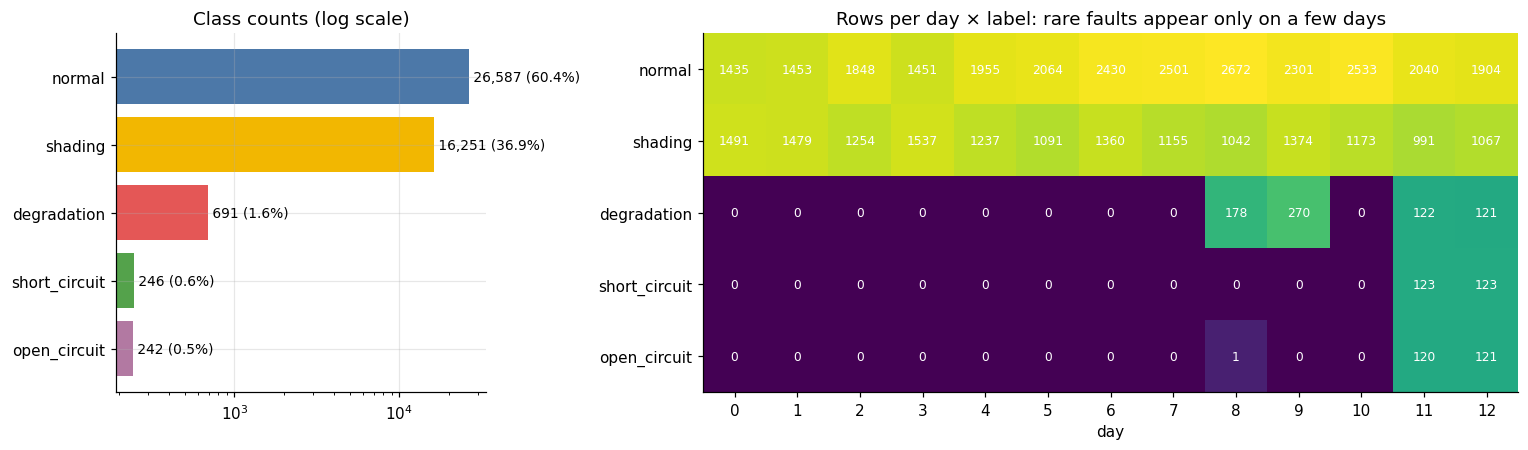

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [1, 2.2]})
vc = train["label"].value_counts().reindex(CL)
ax[0].barh(CL, vc.values, color=[COL[c] for c in CL]); ax[0].set_xscale("log"); ax[0].invert_yaxis()
for i, v in enumerate(vc.values): ax[0].text(v, i, f" {v:,} ({v/len(train):.1%})", va="center", fontsize=9)
ax[0].set_title("Class counts (log scale)")
ct = pd.crosstab(train["day"], train["label"])[CL]
im = ax[1].imshow(np.log1p(ct.T.values), aspect="auto", cmap="viridis")
ax[1].set_yticks(range(5)); ax[1].set_yticklabels(CL); ax[1].set_xticks(range(len(ct))); ax[1].set_xlabel("day")
for i in range(5):
    for j in range(len(ct)):
        ax[1].text(j, i, ct.T.values[i, j], ha="center", va="center", color="w", fontsize=8)
ax[1].set_title("Rows per day × label: rare faults appear only on a few days"); ax[1].grid(False)
plt.tight_layout(); plt.show()

### 1.2 Physical signatures of each fault
In a PV string the current follows irradiance (I ∝ G) and the voltage falls as temperature rises (≈ −0.35 %/°C). Each fault breaks this relationship differently:
* **open circuit** (one group of panels disconnected): voltage and current both drop to about half.
* **short circuit** (two panels shorted): voltage drops by the share of shorted modules (about 12 %); current is unchanged.
* **degradation** (extra series resistance): a smaller voltage drop that scales with current (V = I·R).
* **shading:** current per unit irradiance drops (the irradiance sensor isn't shaded but the panels are), and voltage rises.

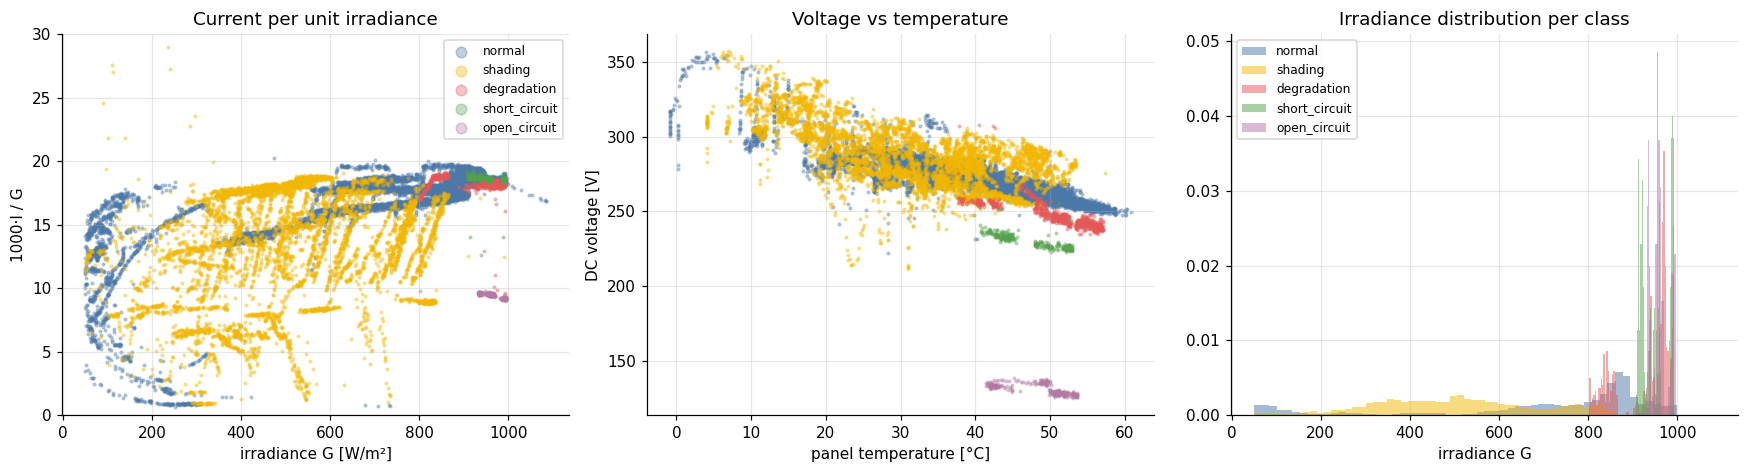

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
s = train.sample(15000, random_state=0)
for c in CL:
    m = (s.label == c) if c in ("normal", "shading") else (train.label == c)
    d = s[m] if c in ("normal", "shading") else train[m]
    ax[0].scatter(d.irradiance, 1000 * d.dc_current / d.irradiance, s=3, alpha=.35, c=COL[c], label=c)
    ax[1].scatter(d.panel_temp, d.dc_voltage, s=3, alpha=.35, c=COL[c])
    ax[2].hist(train.loc[train.label == c, "irradiance"], bins=60, density=True, alpha=.5, color=COL[c], label=c)
ax[0].set(xlabel="irradiance G [W/m²]", ylabel="1000·I / G", title="Current per unit irradiance", ylim=(0, 30))
ax[1].set(xlabel="panel temperature [°C]", ylabel="DC voltage [V]", title="Voltage vs temperature")
ax[2].set(xlabel="irradiance G", title="Irradiance distribution per class"); ax[2].legend(fontsize=8)
ax[0].legend(markerscale=4, fontsize=8); plt.tight_layout(); plt.show()

**Caveat (seen in the right panel):** in training, the hardware faults (short, open, degradation) only occur at high irradiance. A model fed raw values can learn the shortcut "low irradiance ⇒ never a fault", which won't hold on new days. This is why we normalise the signals physically instead of feeding raw values.

## 2. The healthy-plant digital twin
We fit two **Huber (outlier-robust) regressions on `normal` rows only**:
$\hat V = f(\ln G, T)$ and $\widehat{I/G} = g(\ln G, T)$ with terms $[\ln G,\ T,\ (\ln G)^2,\ \ln G\cdot T]$ (single-diode-model intuition: V depends on ln G and T).
Inside cross-validation the twin is **re-fitted on each training fold**, so no validation information leaks into the features.

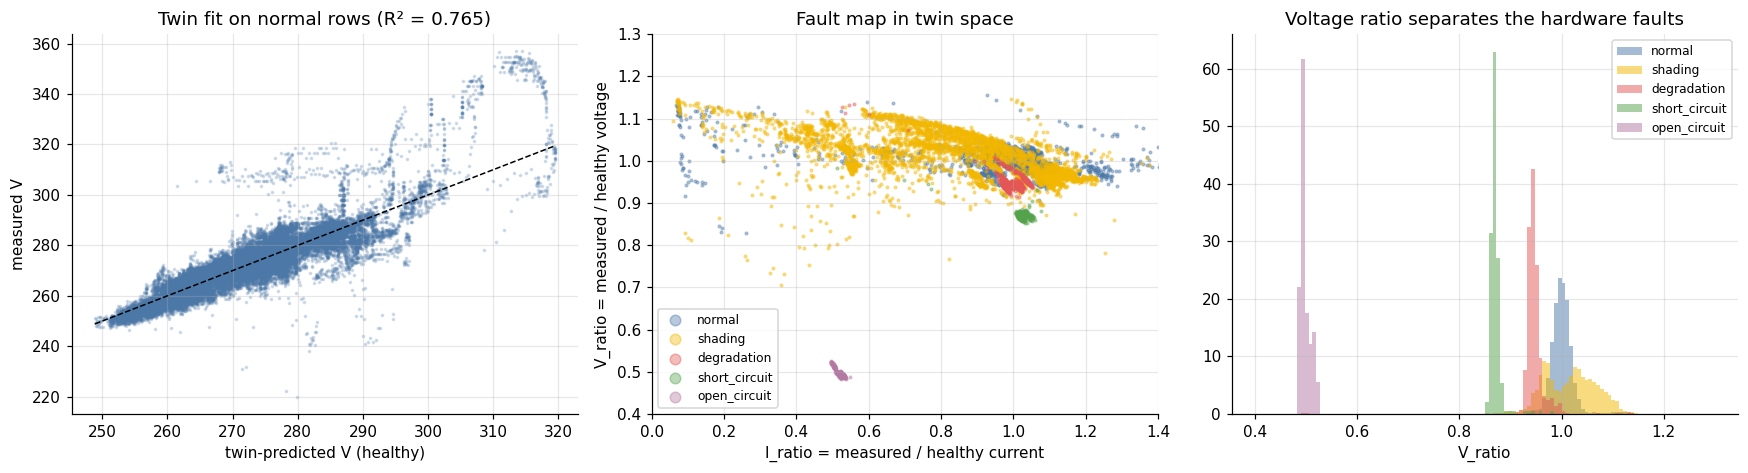

In [5]:
RAW = ["dc_voltage", "dc_current", "irradiance", "panel_temp"]

def base_features(df):
    V, I, G, T = (df[c].astype(float) for c in RAW)
    G = G.clip(lower=1.0)
    f = pd.DataFrame(index=df.index)
    f["V"], f["I"], f["G"], f["T"] = V, I, G, T
    f["lnG"] = np.log(G)
    f["I_per_G"] = 1000 * I / G                     # current per kW/m² (healthy ≈ constant)
    f["P_per_G"] = V * I / G                        # performance-ratio proxy
    f["V_tc"] = V / (1 - 0.0035 * (T - 25))         # temperature-corrected voltage
    f["R_app"] = V / I.clip(lower=0.05)             # apparent load resistance
    return f

class HealthyTwin:
    """Robust model of a HEALTHY plant: expected V and I/G given (G, T). Fitted on normal rows only."""
    @staticmethod
    def _X(f):
        return np.c_[f["lnG"], f["T"], f["lnG"] ** 2, f["lnG"] * f["T"]]
    def fit(self, f, y):
        m = (np.asarray(y) == "normal")
        X = self._X(f[m])
        self.v = HuberRegressor(max_iter=500).fit(X, f.loc[m, "V"])
        self.i = HuberRegressor(max_iter=500).fit(X, f.loc[m, "I_per_G"])
        return self
    def transform(self, f):
        f = f.copy(); X = self._X(f)
        v_hat, i_hat = self.v.predict(X), np.clip(self.i.predict(X), 1e-3, None)
        f["V_hat"], f["I_hat"] = v_hat, i_hat
        f["V_ratio"] = f["V"] / v_hat              # ≈1 healthy, ≈0.88 short, ≈0.5 open
        f["I_ratio"] = f["I_per_G"] / i_hat        # ≈1 healthy, <1 shading, ≈0.5 open
        f["P_ratio"] = f["V_ratio"] * f["I_ratio"]
        f["V_resid"] = f["V"] - v_hat
        f["I_resid"] = f["I_per_G"] - i_hat
        f["V_drop_per_I"] = (v_hat - f["V"]) / f["I"].clip(lower=0.05)   # implied series resistance
        return f

F0, F0_test = base_features(train), base_features(test)
twin_all = HealthyTwin().fit(F0, y)
FA, FA_test = twin_all.transform(F0), twin_all.transform(F0_test)

FS = {
    "raw (4 sensors)": ["V", "I", "G", "T"],
    "raw + ratios": ["V", "I", "G", "T", "I_per_G", "P_per_G", "V_tc", "R_app", "lnG"],
    "twin only": ["V_ratio", "I_ratio", "P_ratio", "V_resid", "I_resid", "V_drop_per_I", "lnG", "T"],
    "twin + raw": ["V", "I", "G", "T", "I_per_G", "P_per_G", "V_tc", "R_app", "lnG",
                   "V_ratio", "I_ratio", "P_ratio", "V_resid", "I_resid", "V_drop_per_I"],
}

fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
nm = y == "normal"
ax[0].scatter(FA.loc[nm, "V_hat"], FA.loc[nm, "V"], s=2, alpha=.2, c=COL["normal"])
lim = [FA.V_hat[nm].min(), FA.V_hat[nm].max()]; ax[0].plot(lim, lim, "k--", lw=1)
r2 = 1 - np.var(FA.V[nm] - FA.V_hat[nm]) / np.var(FA.V[nm])
ax[0].set(xlabel="twin-predicted V (healthy)", ylabel="measured V", title=f"Twin fit on normal rows (R² = {r2:.3f})")
for c in CL:
    m = y == c; idx = np.where(m)[0]
    if m.sum() > 4000: idx = np.random.RandomState(0).choice(idx, 4000, replace=False)
    ax[1].scatter(FA.I_ratio.values[idx], FA.V_ratio.values[idx], s=3, alpha=.4, c=COL[c], label=c)
ax[1].set(xlabel="I_ratio = measured / healthy current", ylabel="V_ratio = measured / healthy voltage",
          title="Fault map in twin space", xlim=(0, 1.4), ylim=(0.4, 1.3)); ax[1].legend(markerscale=4, fontsize=8)
for c in CL:
    ax[2].hist(FA.loc[y == c, "V_ratio"], bins=120, range=(0.4, 1.3), density=True, alpha=.5, color=COL[c], label=c)
ax[2].set(xlabel="V_ratio", title="Voltage ratio separates the hardware faults"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

The **fault map** (middle) is the core idea: in twin space each fault sits in its own region, almost independent of the weather. Open circuit is at (½, ½), short circuit at V≈0.88, degradation just below 1 in V, and shading spreads to the left (lost current).

## 3. Validation design: why Leave-One-Day-Out
The organisers warn that the test set comes from different days. We hold out **one whole day at a time (13 folds)**, train on the other 12, and compute **macro F1 on the pooled out-of-fold predictions**. We pool because a single held-out day usually doesn't contain all five classes, so per-day macro F1 would be undefined.

First, how optimistic is a random split?

raw (4 sensors)    random 5-fold macroF1 = 0.0043 | Leave-One-Day-Out = 0.7517
twin + raw         random 5-fold macroF1 = 0.0033 | Leave-One-Day-Out = 0.8299


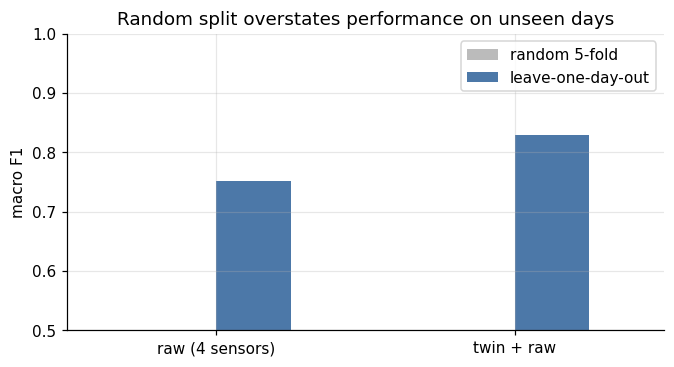

In [6]:
def make_lgbm(seed=SEED, n=300):
    return lgb.LGBMClassifier(n_estimators=n, learning_rate=0.05, num_leaves=15, min_child_samples=30,
                              subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
                              class_weight="balanced", random_state=seed, verbose=-1)

MODELS = {
    "LogReg": lambda: make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=3000, class_weight="balanced")),
    "ExtraTrees": lambda: ExtraTreesClassifier(150, min_samples_leaf=3, class_weight="balanced", n_jobs=-1, random_state=SEED),
    "LightGBM": make_lgbm,
}

def lodo_oof(model_fn, cols, F=F0, y=y, days=days):
    """Leave-One-Day-Out: the twin AND the classifier are refit without the held-out day."""
    oof = np.zeros((len(F), len(CL)))
    for d in np.unique(days):
        tr, va = days != d, days == d
        tw = HealthyTwin().fit(F[tr], y[tr])
        m = model_fn().fit(tw.transform(F[tr])[cols], y[tr])
        p = m.predict_proba(tw.transform(F[va])[cols])
        oof[va] = p[:, [list(m.classes_).index(c) for c in CL]]
    return oof

def mf1(p, yy=y): return f1_score(yy, np.array(CL)[p.argmax(1)] if p.ndim == 2 else p, average="macro")

res_split = {}
for fs in ["raw (4 sensors)", "twin + raw"]:
    rnd = cross_val_predict(make_lgbm(), FA[FS[fs]], y, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method="predict_proba")
    res_split[fs] = (mf1(rnd), mf1(lodo_oof(make_lgbm, FS[fs])))
    print(f"{fs:18s} random 5-fold macroF1 = {res_split[fs][0]:.4f} | Leave-One-Day-Out = {res_split[fs][1]:.4f}")
pd.DataFrame(res_split, index=["random 5-fold", "leave-one-day-out"]).T.plot.bar(figsize=(7, 3.5), rot=0, color=["#bbb", "#4C78A8"])
plt.ylabel("macro F1"); plt.title("Random split overstates performance on unseen days"); plt.ylim(0.5, 1.0); plt.show()

## 4. Ablation: feature sets × models (all scored with LODO)

raw (4 sensors)  | LogReg     | LODO macroF1 = 0.7078 | per-class [0.753 0.686 0.316 0.803 0.982] | 67s
raw (4 sensors)  | ExtraTrees | LODO macroF1 = 0.8258 | per-class [0.92  0.887 0.618 0.708 0.996] | 44s
raw (4 sensors)  | LightGBM   | LODO macroF1 = 0.7517 | per-class [0.915 0.88  0.59  0.603 0.77 ] | 86s
raw + ratios     | LogReg     | LODO macroF1 = 0.7649 | per-class [0.851 0.817 0.374 0.797 0.986] | 94s
raw + ratios     | ExtraTrees | LODO macroF1 = 0.9138 | per-class [0.946 0.923 0.731 0.974 0.996] | 57s
raw + ratios     | LightGBM   | LODO macroF1 = 0.8014 | per-class [0.937 0.919 0.452 0.814 0.886] | 99s
twin only        | LogReg     | LODO macroF1 = 0.7046 | per-class [0.762 0.655 0.33  0.807 0.97 ] | 92s
twin only        | ExtraTrees | LODO macroF1 = 0.9321 | per-class [0.952 0.931 0.798 0.984 0.996] | 54s
twin only        | LightGBM   | LODO macroF1 = 0.8468 | per-class [0.939 0.916 0.582 0.879 0.918] | 96s
twin + raw       | LogReg     | LODO macroF1 = 0.7635 | per-clas

,features,model,macro_F1,normal,shading,degradation,short_circuit,open_circuit,sec
7,twin only,ExtraTrees,0.9321,0.9519,0.9313,0.7978,0.9836,0.9959,54.1494
10,twin + raw,ExtraTrees,0.9190,0.9511,0.9314,0.7444,0.9720,0.9959,68.7796
4,raw + ratios,ExtraTrees,0.9138,0.9460,0.9226,0.7307,0.9737,0.9959,56.5866
14,twin only,LGBM+LogReg blend,0.8827,0.9374,0.9131,0.6618,0.9074,0.9938,0.0000
15,twin + raw,LGBM+LogReg blend,0.8477,0.9219,0.8996,0.5249,0.9357,0.9565,0.0000
8,twin only,LightGBM,0.8468,0.9386,0.9159,0.5823,0.8795,0.9180,96.2943
12,raw (4 sensors),LGBM+LogReg blend,0.8413,0.8921,0.8536,0.6180,0.8571,0.9857,0.0000
11,twin + raw,LightGBM,0.8299,0.9403,0.9220,0.5097,0.9125,0.8651,118.7258
1,raw (4 sensors),ExtraTrees,0.8258,0.9203,0.8871,0.6180,0.7078,0.9959,43.7612
13,raw + ratios,LGBM+LogReg blend,0.8193,0.9161,0.8959,0.4679,0.9255,0.8909,0.0000


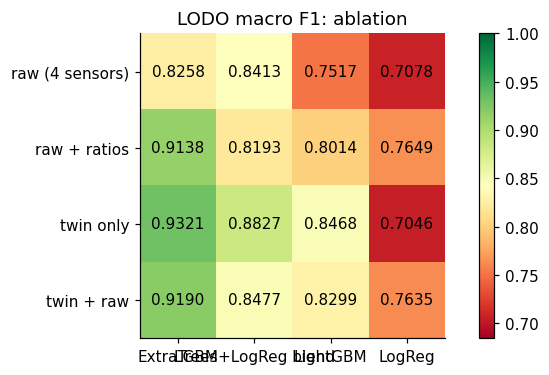

In [8]:
# Faster models + live progress (same selection logic)
MODELS = {
    "LogReg": lambda: make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=500, class_weight="balanced")),
    "ExtraTrees": lambda: ExtraTreesClassifier(80, min_samples_leaf=5, max_features=0.6, class_weight="balanced", n_jobs=-1, random_state=SEED),
    "LightGBM": make_lgbm,
}
rows, OOF = [], {}
for fs, cols in FS.items():
    for mn, fn in MODELS.items():
        t = time.time(); oof = lodo_oof(fn, cols); OOF[(fs, mn)] = oof
        per = f1_score(y, np.array(CL)[oof.argmax(1)], labels=CL, average=None)
        rows.append({"features": fs, "model": mn, "macro_F1": mf1(oof), **{c: v for c, v in zip(CL, per)}, "sec": time.time() - t})
        print(f"{fs:16s} | {mn:10s} | LODO macroF1 = {mf1(oof):.4f} | per-class {np.round(per, 3)} | {time.time()-t:.0f}s", flush=True)
# Blend: LightGBM (strong on normal/shading) + LogReg (extrapolates better on hardware faults)
for fs in FS:
    oof = (OOF[(fs, "LightGBM")] + OOF[(fs, "LogReg")]) / 2; OOF[(fs, "LGBM+LogReg blend")] = oof
    per = f1_score(y, np.array(CL)[oof.argmax(1)], labels=CL, average=None)
    rows.append({"features": fs, "model": "LGBM+LogReg blend", "macro_F1": mf1(oof), **{c: v for c, v in zip(CL, per)}, "sec": 0})
    print(f"{fs:16s} | BLEND      | LODO macroF1 = {mf1(oof):.4f} | per-class {np.round(per, 3)}", flush=True)
abl = pd.DataFrame(rows)
display(abl.round(4).sort_values("macro_F1", ascending=False))
piv = abl.pivot(index="features", columns="model", values="macro_F1").loc[list(FS)]
fig, ax = plt.subplots(figsize=(8, 3.6)); im = ax.imshow(piv.values, cmap="RdYlGn", vmin=piv.values.min() - .02, vmax=1)
ax.set_xticks(range(piv.shape[1])); ax.set_xticklabels(piv.columns); ax.set_yticks(range(piv.shape[0])); ax.set_yticklabels(piv.index)
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]): ax.text(j, i, f"{piv.values[i, j]:.4f}", ha="center", va="center")
ax.set_title("LODO macro F1: ablation"); ax.grid(False); plt.colorbar(im); plt.show()

## 5. The chosen model
We pick the configuration with the **highest LODO macro F1** in the ablation above. The choice is made automatically from cross-validation, never from the leaderboard.

Selected by LODO: ('twin only', 'ExtraTrees') macro F1 = 0.9321
               precision    recall  f1-score   support

       normal     0.9629    0.9412    0.9519     26587
      shading     0.9165    0.9466    0.9313     16251
  degradation     0.7625    0.8365    0.7978       691
short_circuit     0.9917    0.9756    0.9836       246
 open_circuit     0.9918    1.0000    0.9959       242

     accuracy                         0.9421     44017
    macro avg     0.9251    0.9400    0.9321     44017
 weighted avg     0.9429    0.9421    0.9423     44017



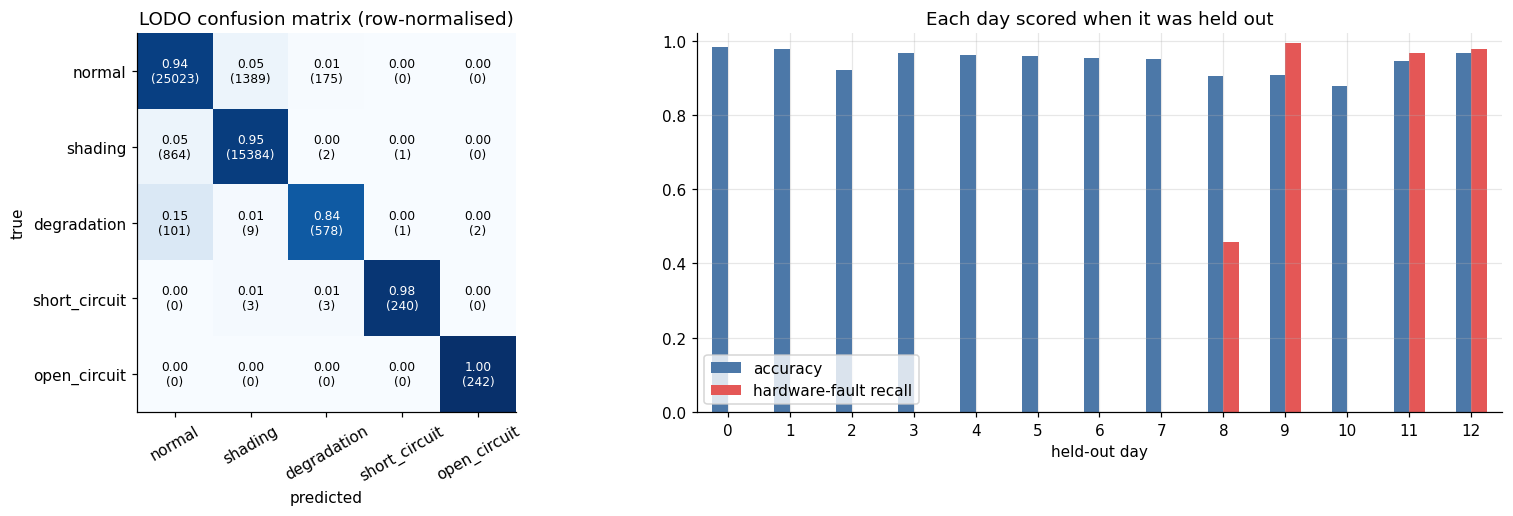

In [9]:
best_key = max(OOF, key=lambda k: mf1(OOF[k]))
BEST_FS, BEST_MODEL = best_key
print("Selected by LODO:", best_key, "macro F1 =", round(mf1(OOF[best_key]), 4))

def fit_predict(model_name, cols, Ftr, ytr, Fte):
    """Fit the selected model on (Ftr, ytr), return class probabilities on Fte in CL order."""
    names = ["LightGBM", "LogReg"] if model_name == "LGBM+LogReg blend" else [model_name]
    P = 0
    for n in names:
        m = MODELS[n]().fit(Ftr[cols], ytr)
        P = P + m.predict_proba(Fte[cols])[:, [list(m.classes_).index(c) for c in CL]]
    return P / len(names)

oof_best = OOF[best_key]
pred_best = np.array(CL)[oof_best.argmax(1)]
print(classification_report(y, pred_best, labels=CL, digits=4))
cm = confusion_matrix(y, pred_best, labels=CL)
cmn = cm / cm.sum(1, keepdims=True)
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
ax[0].imshow(cmn, cmap="Blues", vmin=0, vmax=1)
for i in range(5):
    for j in range(5): ax[0].text(j, i, f"{cmn[i, j]:.2f}\n({cm[i, j]})", ha="center", va="center", fontsize=8, color="w" if cmn[i, j] > .5 else "k")
ax[0].set_xticks(range(5)); ax[0].set_xticklabels(CL, rotation=30); ax[0].set_yticks(range(5)); ax[0].set_yticklabels(CL)
ax[0].set(xlabel="predicted", ylabel="true", title="LODO confusion matrix (row-normalised)"); ax[0].grid(False)
hw = np.isin(y, CL[2:])
per_day = pd.DataFrame({
    "accuracy": [np.mean(pred_best[days == d] == y[days == d]) for d in np.unique(days)],
    "hardware-fault recall": [np.mean(pred_best[(days == d) & hw] == y[(days == d) & hw]) if np.any((days == d) & hw) else np.nan for d in np.unique(days)],
}, index=np.unique(days))
per_day.plot.bar(ax=ax[1], rot=0, color=["#4C78A8", "#E45756"])
ax[1].set(title="Each day scored when it was held out", xlabel="held-out day", ylim=(0, 1.02)); ax[1].legend(loc="lower left")
plt.tight_layout(); plt.show()

## 6. Overfitting / underfitting diagnostics
### 6.1 Train vs validation learning curves (boosting rounds)
For every LODO fold we track multi-class log-loss on the training days and on the held-out day as trees are added. If the model were overfitting, the validation curve would bend back up while the training curve kept falling.

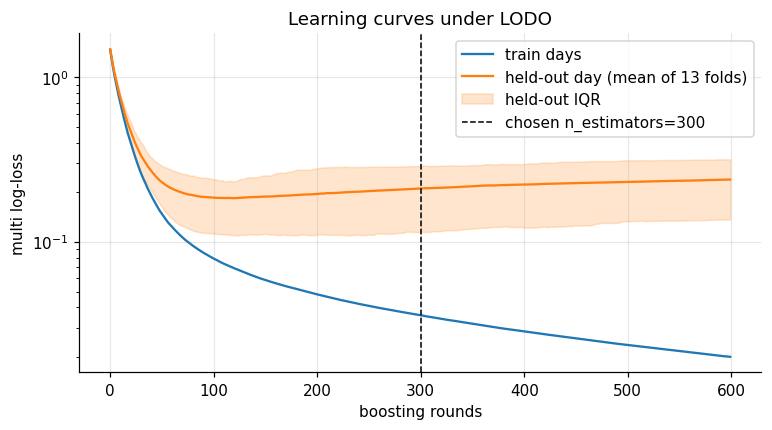

best mean valid round = 119 | valid logloss @300 = 0.2102 vs min 0.1840


In [10]:
curves_tr, curves_va = [], []
for d in np.unique(days):
    tr, va = days != d, days == d
    tw = HealthyTwin().fit(F0[tr], y[tr]); Xtr, Xva = tw.transform(F0[tr])[FS[BEST_FS]], tw.transform(F0[va])[FS[BEST_FS]]
    m = make_lgbm(n=600); ev = {}
    m.fit(Xtr, y[tr], eval_set=[(Xtr, y[tr]), (Xva, y[va])], eval_names=["train", "valid"], eval_metric="multi_logloss",
          callbacks=[lgb.record_evaluation(ev)])
    curves_tr.append(ev["train"]["multi_logloss"]); curves_va.append(ev["valid"]["multi_logloss"])
ctr, cva = np.mean(curves_tr, 0), np.mean(curves_va, 0)
plt.figure(figsize=(8, 4))
plt.plot(ctr, label="train days"); plt.plot(cva, label="held-out day (mean of 13 folds)")
plt.fill_between(range(len(cva)), np.percentile(curves_va, 25, 0), np.percentile(curves_va, 75, 0), alpha=.2, color="C1", label="held-out IQR")
plt.axvline(300, ls="--", c="k", lw=1, label="chosen n_estimators=300"); plt.yscale("log")
plt.xlabel("boosting rounds"); plt.ylabel("multi log-loss"); plt.title("Learning curves under LODO"); plt.legend(); plt.show()
print(f"best mean valid round = {cva.argmin()} | valid logloss @300 = {cva[299]:.4f} vs min {cva.min():.4f}")

### 6.2 Learning curve over number of training days
How does held-out performance change as we train on more days? We evaluate on fault days 11 and 12 (each held out in turn, so the other one still provides short/open-circuit examples) and vary how many of the remaining days are used for training.

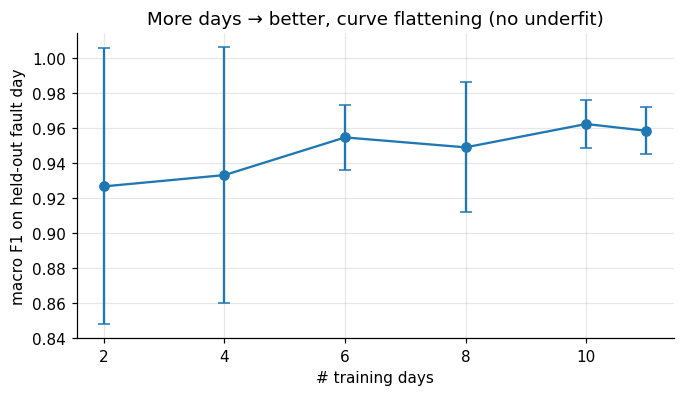

In [11]:
rng = np.random.RandomState(SEED); lc = []
for k in [2, 4, 6, 8, 10, 11]:
    scores = []
    for rep in range(3):
        for hold in [11, 12]:
            other = 23 - hold
            pool = [d for d in np.unique(days) if d not in (11, 12)]
            use = list(rng.choice(pool, size=min(k - 1, len(pool)), replace=False)) + [other]
            tr, va = np.isin(days, use), days == hold
            tw = HealthyTwin().fit(F0[tr], y[tr])
            P = fit_predict(BEST_MODEL, FS[BEST_FS], tw.transform(F0[tr]), y[tr], tw.transform(F0[va]))
            p = np.array(CL)[P.argmax(1)]
            scores.append(f1_score(y[va], p, average="macro"))
    lc.append((k, np.mean(scores), np.std(scores)))
lc = np.array(lc)
plt.figure(figsize=(7, 3.6)); plt.errorbar(lc[:, 0], lc[:, 1], yerr=lc[:, 2], marker="o", capsize=4)
plt.xlabel("# training days"); plt.ylabel("macro F1 on held-out fault day"); plt.title("More days → better, curve flattening (no underfit)"); plt.show()

### 6.3 Seed stability and robustness across irradiance

LightGBM LODO macro F1 over 3 seeds: [0.8595 0.8659 0.8468] → std 0.0079


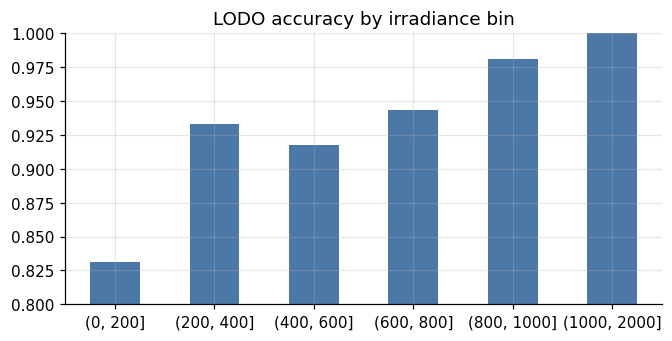

In [12]:
seed_scores = [mf1(lodo_oof(lambda s=s: make_lgbm(seed=s), FS[BEST_FS])) for s in [1, 2]] + [mf1(OOF[(BEST_FS, "LightGBM")])]
print("LightGBM LODO macro F1 over 3 seeds:", np.round(seed_scores, 4), "→ std", np.std(seed_scores).round(4))
bins = pd.cut(train.irradiance, [0, 200, 400, 600, 800, 1000, 2000])
acc_bin = pd.Series(pred_best == y).groupby(bins.values).mean()
acc_bin.plot.bar(figsize=(7, 3.2), rot=0, color="#4C78A8"); plt.ylim(0.8, 1); plt.title("LODO accuracy by irradiance bin"); plt.show()

### 6.4 Adversarial validation: how different is the test set?
We train a classifier to tell training rows from test rows. AUC ≈ 0.5 means the test set looks like training data. Twin features should show **less** shift than raw sensor values, because they remove the weather.

In [13]:
adv = {}
for fs in ["raw (4 sensors)", "twin only"]:
    X = pd.concat([FA[FS[fs]], FA_test[FS[fs]]]); z = np.r_[np.zeros(len(FA)), np.ones(len(FA_test))]
    pz = cross_val_predict(lgb.LGBMClassifier(n_estimators=200, num_leaves=15, verbose=-1, random_state=SEED), X, z,
                           cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method="predict_proba")[:, 1]
    adv[fs] = roc_auc_score(z, pz)
print({k: round(v, 4) for k, v in adv.items()})

{'raw (4 sensors)': np.float64(0.9815), 'twin only': np.float64(0.991)}


## 7. What the model uses: feature importance

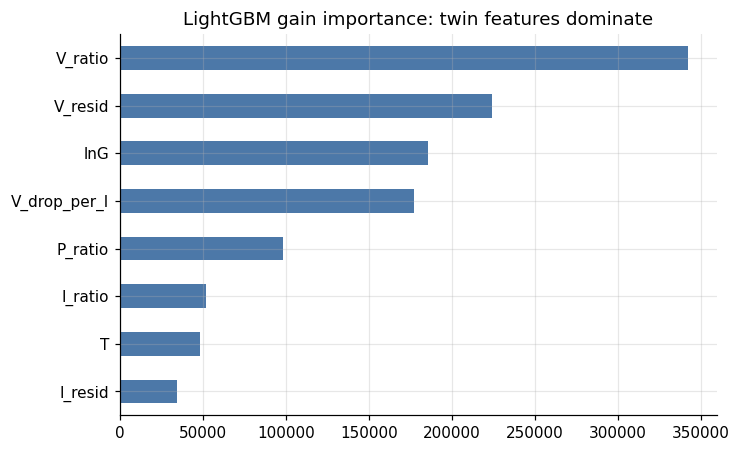

In [14]:
lgb_full = make_lgbm().fit(FA[FS[BEST_FS]], y)
imp = pd.Series(lgb_full.booster_.feature_importance("gain"), index=FS[BEST_FS]).sort_values()
imp.plot.barh(figsize=(7, 4.5), color="#4C78A8"); plt.title("LightGBM gain importance: twin features dominate"); plt.show()

## 8. Final model → test predictions
The twin and the classifier are refit on **all 13 days** with exactly the configuration validated above (no tuning on the leaderboard).

submission.csv written from ('twin only', 'ExtraTrees')
submission_runnerup.csv written from ('twin + raw', 'ExtraTrees') LODO 0.919 | agreement with main: 0.9818


,train share,test predicted share
normal,0.6040,0.5762
shading,0.3692,0.3118
degradation,0.0157,0.0368
short_circuit,0.0056,0.0377
open_circuit,0.0055,0.0374


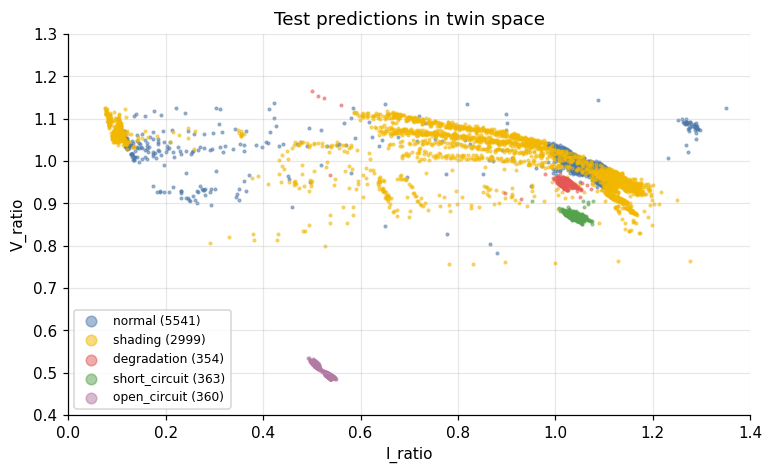

,id,label
0,102668,normal
1,100729,short_circuit
2,104683,normal
3,105575,normal
4,101797,shading


In [15]:
proba_test = fit_predict(BEST_MODEL, FS[BEST_FS], FA, y, FA_test)
pred_test = np.array(CL)[proba_test.argmax(1)]
sub = pd.DataFrame({"id": test["id"], "label": pred_test})
sub.to_csv("submission.csv", index=False)
print("submission.csv written from", best_key)
# Second final pick: the runner-up configuration by LODO, as a hedge
second_key = sorted(OOF, key=lambda k: -mf1(OOF[k]))[1]
p2 = fit_predict(second_key[1], FS[second_key[0]], FA, y, FA_test)
pd.DataFrame({"id": test["id"], "label": np.array(CL)[p2.argmax(1)]}).to_csv("submission_runnerup.csv", index=False)
print("submission_runnerup.csv written from", second_key, "LODO", round(mf1(OOF[second_key]), 4),
      "| agreement with main:", round(np.mean(np.array(CL)[p2.argmax(1)] == pred_test), 4))
cmp = pd.DataFrame({"train share": pd.Series(y).value_counts(normalize=True), "test predicted share": sub.label.value_counts(normalize=True)}).reindex(CL)
display(cmp.round(4))
fig, ax = plt.subplots(figsize=(8, 4.5))
for c in CL:
    m = pred_test == c
    ax.scatter(FA_test.I_ratio[m], FA_test.V_ratio[m], s=3, alpha=.5, c=COL[c], label=f"{c} ({m.sum()})")
ax.set(xlim=(0, 1.4), ylim=(0.4, 1.3), xlabel="I_ratio", ylabel="V_ratio", title="Test predictions in twin space"); ax.legend(markerscale=4, fontsize=8); plt.show()
sub.head()

In [16]:
from google.colab import files
files.download("submission.csv")
files.download("submission_runnerup.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 9. Summary
* **Validation:** Leave-One-Day-Out (13 folds), with the twin refit inside every fold and macro F1 on pooled out-of-fold predictions. The random split vs LODO comparison in Section 3 shows why this matters.
* **Features:** a physics-based healthy-plant twin (voltage ratio, current ratio, power ratio, residuals, implied series resistance), plus temperature-corrected voltage, current per irradiance, performance ratio and apparent resistance.
* **Model selection:** automatic, from the LODO ablation of 4 feature sets × 4 model families (Section 4).
* **Overfitting checks:** learning curves (6.1), more training days → better held-out score (6.2), seed stability and irradiance robustness (6.3), and adversarial validation of the test shift (6.4).
* **Most-confused faults:** see the confusion matrix in Section 5. The hardest boundary is `degradation` vs `normal`, because a small extra series resistance changes the voltage only slightly.
* **Reproducibility:** fixed seeds; the notebook writes `submission.csv` (main) and `submission_runnerup.csv` (hedge pick).